## Final Class: The Regression Arena
### Linear and Logistic Regression with 802 Pokemon

---

### In this notebook

Every Pokemon has six **base stats** (HP, Attack, Defense, Special Attack, Special Defense and Speed), a height, a weight, one or two types, and a **base experience** value: the experience points (XP) your Pokemon earns for defeating it. Some Pokemon are also **legendary**. We use them to learn how a model learns from data: first by predicting a number (XP), then by predicting a yes or no answer (legendary or not).

1. Linear regression: modeling relationships between variables
2. Cost functions
3. Multiple linear regression
4. Gradient descent: gradients, learning rate and convergence
5. Evaluating regression models: MAE, MSE, RMSE and R-squared
6. From regression to classification
7. Logistic regression: the sigmoid function and predicted probabilities
8. Decision boundaries and log loss
9. The bias-variance trade-off and regularization
10. Final challenge: the Pokemon Designer and the XP Prediction Tournament

### Interactive plots

Each **Interactive** section is a plot in which you control hyperparameters of the algorithm to optimize it or go against it.

| Interactives | Slider Controls | The idea it teaches |
|---|---|---|
| Interactive 1 Fit the Line by Hand | a human regression model, scored in stars | residuals, MSE, the cost map |
| Interactive 2 Lost in the Fog | gradient descent, walking blind to the valley | gradients and the learning rate |
| Interactive 3 The Gradient Descent Race | a bettor on four racing learning rates | convergence and divergence |
| Interactive 4 Human vs. Machine | a Pokemon expert against logistic regression | probabilities and log loss |
| Interactive 5 The Legendary Research Lab | a lab director with a budget | thresholds and the cost of mistakes |
| Interactive 6 Ghost Curves | a scientist rerunning the same experiment 20 times | bias and variance |
| Interactive 7 The Pokemon Designer | a game designer completing missions | using both models together |

*Data: "Pokemon" from the {pokemon} R package by William Amorim (based on PokeAPI), published by [TidyTuesday](https://github.com/rfordatascience/tidytuesday), April 2025. Legendary and mythical Pokemon are labelled using the National Pokedex.*

### Setup and data loading

Run this cell first. Besides our usual libraries, it loads **ipywidgets** (sliders and buttons) and **plotly** (charts you can hover over, rotate and animate). Both are already installed in Google Colab.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, clear_output, HTML

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

# Fixed colors used in every chart
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"
YELLOW, PURPLE, GRAY = "#eda100", "#6250d6", "#c3c2b7"

def slider(kind, value, lo, hi, step, label):
    # a slider that redraws only when you let go of it
    return kind(value=value, min=lo, max=hi, step=step, description=label,
                continuous_update=False, style={"description_width": "initial"})

def play(draw, controls, buttons=()):
    screen = widgets.Output()
    def refresh(*args):
        with screen:
            clear_output(wait=True)
            draw(**{name: w.value for name, w in controls.items()})
    for w in controls.values():
        w.observe(refresh, names="value")
    row = []
    for label, action, style in buttons:
        b = widgets.Button(description=label, button_style=style, layout=widgets.Layout(width="auto"))
        b.on_click(lambda btn, action=action: (action(), refresh()))
        row.append(b)
    display(widgets.HBox(list(controls.values()), layout=widgets.Layout(flex_flow="row wrap")), widgets.HBox(row), screen)
    refresh()

The data file is stored on GitHub. The link points to one fixed version of the file, so everyone in class loads exactly the same data.

In [ ]:
URL = ("https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
       "54ea581e1352f6c55b9343feb77df0fc29c78621/data/2025/2025-04-01/pokemon_df.csv")

raw = pd.read_csv(URL)
print("Rows and columns:", raw.shape)
raw[["pokemon", "species_id", "type_1", "height", "weight", "base_experience", "hp", "attack", "speed"]].head()

Rows and columns: (949, 22)


,pokemon,species_id,type_1,height,weight,base_experience,hp,attack,speed
0,bulbasaur,1,grass,0.7,6.9,64,45,49,45
1,ivysaur,2,grass,1.0,13.0,142,60,62,60
2,venusaur,3,grass,2.0,100.0,236,80,82,80
3,charmander,4,fire,0.6,8.5,62,39,52,65
4,charmeleon,5,fire,1.1,19.0,142,58,64,80


### The columns we use

| Column | Meaning |
|---|---|
| `pokemon` | name of the Pokemon |
| `species_id` | National Pokedex number (Bulbasaur is 1, Pikachu is 25) |
| `hp`, `attack`, `defense` | base stats: health, physical attack, physical defense |
| `special_attack`, `special_defense`, `speed` | base stats: special attack, special defense, speed |
| `base_experience` | XP your Pokemon earns for defeating this Pokemon |
| `height`, `weight` | in meters and kilograms |
| `type_1`, `type_2` | the Pokemon's types, such as fire or water (`type_2` is empty for single-type Pokemon) |
| `generation_id` | the generation of games that introduced it (1 to 7) |

### Preparing the data

The file also contains alternate forms, such as Mega Evolutions, whose `id` is above 10000. We keep **one row per species** (the 802 Pokemon of Generations 1 to 7) and add two columns:

- `total`: the **base stat total**, the sum of the six stats. Players use it as a quick measure of how strong a Pokemon is.
- `legendary`: 1 if the Pokemon is legendary or mythical, 0 if not. The file has no such column, so we mark them from their National Pokedex numbers.

In [ ]:
STATS = ["hp", "attack", "defense", "special_attack", "special_defense", "speed"]

poke = raw[raw["id"] < 10000].copy()                 # one row per species
poke["total"] = poke[STATS].sum(axis=1)               # base stat total
poke["generation_id"] = poke["generation_id"].astype(int)

# National Pokedex numbers of legendary and mythical Pokemon, Generations 1 to 7
LEGENDARY = ([144, 145, 146, 150, 151] +                          # Gen 1: Articuno ... Mew
             [243, 244, 245, 249, 250, 251] +                     # Gen 2: Raikou ... Celebi
             list(range(377, 387)) +                              # Gen 3: Regirock ... Deoxys
             list(range(480, 494)) +                              # Gen 4: Uxie ... Arceus
             [494] + list(range(638, 650)) +                      # Gen 5: Victini, Cobalion ... Genesect
             list(range(716, 722)) +                              # Gen 6: Xerneas ... Volcanion
             [772, 773] + list(range(785, 793)) + [800, 801, 802])  # Gen 7: Type: Null ... Marshadow
poke["legendary"] = poke["species_id"].isin(LEGENDARY).astype(int)

print("Pokemon species:", len(poke), "   Legendary or mythical:", poke["legendary"].sum())

Pokemon species: 802    Legendary or mythical: 67


## 1. Introduction to Linear Regression

**Regression** means predicting a **number**. Our first question:

> If we know a Pokemon's base stat total, can we predict how much XP it gives when defeated?

- The **feature** (input, x) is the base stat total, `total`.
- The **target** (output, y) is the XP, `base_experience`.

A scatter plot shows the relationship.

This chart is **interactive**: hover over a dot to see which Pokemon it is, and drag a box to zoom in (double-click to zoom out). Find the dots that sit far **above** the band. Who are they?

In [ ]:
fig = px.scatter(poke, x="total", y="base_experience", hover_name="pokemon",
                 hover_data={"hp": True, "generation_id": True},
                 labels={"total": "Base stat total", "base_experience": "Base experience (XP)"},
                 title="Each dot is one Pokemon: hover to find out who", height=420)
fig.update_traces(marker=dict(color=BLUE, size=7, opacity=0.6))
fig.show()

The dots form a clear upward band: stronger Pokemon give more XP. A straight line could summarize this pattern:

$$\hat{y} = b_0 + b_1 x$$

| Symbol | Name | Meaning |
|---|---|---|
| $\hat{y}$ ("y hat") | prediction | the XP the line predicts |
| $b_0$ | intercept | where the line crosses x = 0 |
| $b_1$ | slope | how much $\hat{y}$ changes when x increases by 1 |

Finding good values of $b_0$ and $b_1$ from data is called **fitting** the model. The model is **linear** because the prediction is a constant plus a number times each feature.

### Residuals

For each Pokemon, the **residual** is the vertical gap between its dot and the line:

$$\text{residual} = y - \hat{y} = \text{actual} - \text{predicted}$$

A positive residual means the line predicted too little XP; a negative residual means it predicted too much. A good line has **small residuals overall**.

### Data Story 1 The Pokemon Worth the Most XP

Look at the scatter plot again: a few dots sit far **above** the band. Which Pokemon are they?

In [ ]:
poke.sort_values("base_experience", ascending=False)[["pokemon", "total", "hp", "base_experience"]].head(6)

,pokemon,total,hp,base_experience
241,blissey,540,255,608
112,chansey,450,250,395
530,audino,445,103,390
492,arceus,720,120,324
486,giratina-altered,680,150,306
483,palkia,680,90,306


**Blissey** gives 608 XP, more than any legendary, even though its base stat total (540) is only average for a fully evolved Pokemon. Its relative **Chansey** gives 395 XP with a total of just 450. Experienced players know these Pokemon: defeating them is a classic way to level up quickly. **Audino** and **Happiny** (Blissey's baby form) are similar.

All four are "healer" Pokemon with very high HP. The game designers simply chose to give them a lot of XP, and the base stat total cannot see that choice.

**Lesson:** a few points can be very far from the pattern for reasons that are not in our features. Keep them in mind; they will matter in Data Story 2.

## 2. Cost Functions

How do we decide which line is "best"? We use a **cost function**: one number that measures how bad a line is. The best line is the one with the **lowest cost**.

The most common cost for regression is the **mean squared error (MSE)**:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2$$

In words: square every residual, then take the average. A squared residual is literally the **area of a square** whose side is the residual, so the MSE is the **average area** of these squares. Why square?

1. Positive and negative residuals would cancel out if we simply added them. Squares are never negative.
2. Squaring makes big misses count much more than small ones (a miss of 10 costs 100; a miss of 2 costs 4).

In [ ]:
x_total = poke["total"].to_numpy()
y_xp = poke["base_experience"].to_numpy()

def mse_cost(b0, b1):
    predictions = b0 + b1 * x_total
    return np.mean((y_xp - predictions) ** 2)

print(f"MSE of the line y = -80 + 0.5x: {mse_cost(-80, 0.5):.1f}")

MSE of the line y = -80 + 0.5x: 1355.4


### Interactive 1 Fit the Line by Hand

Move the sliders to shrink the orange squares (the squared residuals of 15 example Pokemon). Your score is the MSE over all 802 Pokemon, and it earns a rank from Rookie to Pokemon Master (3 stars).

The right panel is new: the **cost map**. Every point on it is one possible line, and the color rings show its cost, like the height lines on a hiking map. The orange dot is your current line, and the gray trail is every line you have tried. Fitting a model means finding the lowest point of this map.

**Class challenge:** reach 3 stars in as few attempts as you can, and post your attempts on the board. Press **Reveal the best line** only when your instructor says so.

In [ ]:
# @title Interactive 1: Fit the Line by Hand (run this cell, then play)
sample = poke.sample(15, random_state=1)                 # the 15 Pokemon whose squares we draw
xs = np.linspace(170, 730, 100)
best_b1, best_b0 = np.polyfit(x_total, y_xp, 1)          # kept secret until you press Reveal
best_mse = mse_cost(best_b0, best_b1)
G0, G1 = np.meshgrid(np.linspace(-250, 100, 80), np.linspace(0, 1, 80))
GRID_COST = np.vectorize(mse_cost)(G0, G1)
RANKS = ["Rookie (0 stars)", "Trainer (1 star)", "Gym Leader (2 stars)", "Pokemon Master (3 stars)"]
trail, line_game = [], {"revealed": False}

def draw_line_game(intercept, slope):
    mse = mse_cost(intercept, slope)
    if not trail or trail[-1][:2] != (intercept, slope):
        trail.append((intercept, slope, mse))
    pred = intercept + slope * sample["total"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

    # left: the data, your line and the squared residuals
    ax1.scatter(poke["total"], poke["base_experience"], color=GRAY, alpha=0.4, s=12)
    for xi, yi, pi in zip(sample["total"], sample["base_experience"], pred):
        side = abs(yi - pi)
        ax1.add_patch(plt.Rectangle((xi, min(yi, pi)), side, side, color=ORANGE, alpha=0.3))
    ax1.scatter(sample["total"], sample["base_experience"], color=BLUE, s=30, zorder=3)
    ax1.plot(xs, intercept + slope * xs, color="black", lw=2, label="your line")
    if line_game["revealed"]:
        ax1.plot(xs, best_b0 + best_b1 * xs, color=GREEN, lw=2, ls="--", label="best line")
    ax1.set(xlim=(150, 750), ylim=(-50, 650), aspect="equal", xlabel="Base stat total",
            ylabel="Base experience (XP)", title=f"Your MSE = {mse:,.1f}\n(the average area of the squares)")
    ax1.legend(loc="upper left")

    # right: where your line sits on the cost map
    ax2.contourf(G0, G1, GRID_COST, levels=np.logspace(3.05, 5.2, 18), cmap="Blues_r", alpha=0.85)
    t = np.array(trail)
    ax2.plot(t[:, 0], t[:, 1], ".-", color="white", lw=1, ms=5, label="your trail")
    ax2.scatter(intercept, slope, s=160, color=ORANGE, edgecolor="black", zorder=4, label="you are here")
    if line_game["revealed"]:
        ax2.scatter(best_b0, best_b1, marker="*", s=400, color=GREEN, edgecolor="black", zorder=5, label="the best line")
    ax2.set(xlabel="intercept b0", ylabel="slope b1", title="The cost map: every point is one line")
    ax2.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

    stars = 3 if mse <= 1.002 * best_mse else 2 if mse <= 1.02 * best_mse else 1 if mse <= 1.15 * best_mse else 0
    print(f"Rank: {RANKS[stars]}   |   attempts: {len(trail)}   |   your best MSE so far: {t[:, 2].min():,.1f}")

def reveal_line():
    line_game["revealed"] = True

play(draw_line_game,
     {"intercept": slider(widgets.IntSlider, -80, -250, 100, 1, "intercept b0"),
      "slope": slider(widgets.FloatSlider, 0.50, 0.0, 1.0, 0.01, "slope b1")},
     [("Reveal the best line", reveal_line, "success"), ("Clear my trail", trail.clear, "")])

# Without the sliders, call the game directly: draw_line_game(-80, 0.5)

Output()

**Debrief.** Look at the shape of the cost map. The low-cost region is a long, thin **valley** running diagonally: if you raise the slope, you must lower the intercept to stay in it. That is why it was hard to reach 3 stars by moving one slider at a time. Keep this valley in mind for Section 4.

### The answer: scikit-learn's best line

scikit-learn's `LinearRegression` finds the line with the lowest possible MSE for us. The features `X` must be a **table** (two square brackets), and the target `y` is one column.

In [ ]:
from sklearn.linear_model import LinearRegression

simple = LinearRegression()
simple.fit(poke[["total"]], poke["base_experience"])       # X is a table (2D), y is a column

b0, b1 = simple.intercept_, simple.coef_[0]
print(f"Best line: XP = {b0:.2f} + {b1:.3f} x total")

Best line: XP = -102.50 + 0.578 x total


In [ ]:
print(f"MSE of the best line: {mse_cost(b0, b1):.1f}")

new = pd.DataFrame({"total": [300, 500]})
print("Predicted XP for totals of 300 and 500:", simple.predict(new).round(1))

MSE of the best line: 1170.9
Predicted XP for totals of 300 and 500: [ 71.  186.6]


Did anyone get below this MSE? Nobody can: **no other line** has a lower cost.

**Reading the line:**

- **Slope 0.578:** each extra point of base stat total goes with about 0.58 more XP. A Pokemon that is 100 points stronger gives about 58 more XP.
- **Intercept -102.5:** the predicted XP for a Pokemon with a total of 0. This has no real meaning, since no Pokemon has a total of 0 (the weakest has 175). The intercept just positions the line.

For linear regression there is a formula that jumps straight to the bottom of the cost map, and `LinearRegression` uses it. For most other models (logistic regression, neural networks) there is **no** such formula. They find the bottom step by step, with **gradient descent**, which is what you were doing by hand.

### Exercise 1 Cost Functions and Simple Regression

1. Compute the MSE of the lines ($b_0$ = -120, $b_1$ = 0.6) and ($b_0$ = -50, $b_1$ = 0.45). Which line is better? Find both on the cost map: are they inside the valley?
2. Fit a simple regression of `weight` on `height`. What is the slope, and what does it mean in kilograms per meter?

In [ ]:
# Your code here

## 3. Multiple Linear Regression

The base stat total adds the six stats together, as if each were worth the same. With **multiple regression**, each stat gets its own coefficient:

$$\hat{y} = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_p x_p$$

Each coefficient $b_j$ is the change in the prediction when $x_j$ increases by 1 **and all other features stay the same**. This "holding the others fixed" idea is what makes multiple regression powerful.

In [ ]:
multi = LinearRegression().fit(poke[STATS], poke["base_experience"])
coefs = pd.Series(multi.coef_, index=STATS)
print(coefs.round(2))

hp                 0.91
attack             0.38
defense            0.45
special_attack     0.47
special_defense    0.73
speed              0.59
dtype: float64


### Data Story 2 Is HP Really Worth Twice as Much XP as Attack?

The multiple regression says one extra point of **HP** is worth about 0.91 XP, while one extra point of **Attack** is worth only about 0.38 XP. Do the game designers really value HP more than twice as much?

Remember the healer Pokemon from Data Story 1. They have huge HP **and** huge XP. Let's refit the model without those four Pokemon.

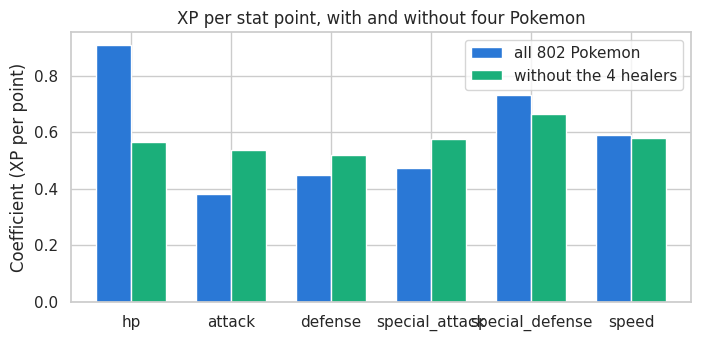

,all 802 Pokemon,without the 4 healers
hp,0.91,0.57
attack,0.38,0.54
defense,0.45,0.52
special_attack,0.47,0.58
special_defense,0.73,0.67
speed,0.59,0.58


In [ ]:
HEALERS = ["chansey", "blissey", "audino", "happiny"]
no_healers = poke[~poke["pokemon"].isin(HEALERS)]
multi_nh = LinearRegression().fit(no_healers[STATS], no_healers["base_experience"])

compare = pd.DataFrame({"all 802 Pokemon": multi.coef_, "without the 4 healers": multi_nh.coef_}, index=STATS)
compare.plot(kind="bar", figsize=(8, 3.5), color=[BLUE, GREEN], width=0.7)
plt.title("XP per stat point, with and without four Pokemon")
plt.ylabel("Coefficient (XP per point)")
plt.xticks(rotation=0)
plt.show()
compare.round(2)

Without the four healers, the HP coefficient falls from 0.91 to 0.57, and all six stats are worth about the **same** XP per point (between 0.52 and 0.67). That matches the simple model's slope of 0.58: XP is mostly a function of the **total**, not of any special stat.

So four Pokemon out of 802 were enough to make HP look twice as valuable.

**Lesson:** a coefficient can be driven by a handful of unusual rows. Before you tell a story about a coefficient, check whether a few points are responsible for it.

### Exercise 2 Multiple Regression

Fit a multiple regression of `base_experience` on `total`, `height` and `weight`. Is the coefficient of `total` close to the simple model's 0.578? Predict the XP of a Pokemon with a total of 500, a height of 1.5 m and a weight of 50 kg.

<details>
<summary><b>Hint</b></summary>

For a prediction, build a one-row table with the same column names used in `fit`, for example `pd.DataFrame({"total": [500], "height": [1.5], "weight": [50]})`.

</details>

In [ ]:
# Your code here

## 4. Gradient Descent

Imagine standing on a hillside in thick fog, trying to reach the lowest point of the valley. You cannot see the valley, but you can feel which way the ground slopes under your feet. So you take a step downhill, feel again, and repeat.

**Gradient descent** does exactly this on the cost bowl:

1. Start with any values, for example $b_0 = 0$ and $b_1 = 0$.
2. Compute the **gradient**: the direction in which the cost rises fastest.
3. Take a step in the **opposite** direction: $b \leftarrow b - \text{learning rate} \times \text{gradient}$.
4. Repeat until the cost stops going down. This is called **convergence**.

For the MSE, the gradients are

$$\frac{\partial\, \text{MSE}}{\partial b_0} = -\frac{2}{n}\sum_{i}\left(y_i - \hat{y}_i\right) \qquad \frac{\partial\, \text{MSE}}{\partial b_1} = -\frac{2}{n}\sum_{i} x_i\left(y_i - \hat{y}_i\right)$$

In plain words: the **average residual** tells us whether to move the line up or down, and the **average residual times x** tells us how to tilt it.

### Scale the feature first

Gradient descent works best when features are centered near 0 with a similar spread. We **standardize** the base stat total: subtract the mean and divide by the standard deviation. A value of +1 now means "one standard deviation stronger than the average Pokemon".

In [ ]:
x = ((poke["total"] - poke["total"].mean()) / poke["total"].std()).to_numpy()
y = poke["base_experience"].to_numpy()
print(f"Scaled x: mean = {x.mean():.2f}, standard deviation = {x.std(ddof=1):.2f}")

Scaled x: mean = 0.00, standard deviation = 1.00


In [ ]:
def gradient_descent(x, y, learning_rate, n_steps):
    b0, b1 = 0.0, 0.0                              # 1. start anywhere
    history = []
    for step in range(n_steps):
        error = y - (b0 + b1 * x)                  # residuals with the current line
        grad_b0 = -2 * error.mean()                # 2. the gradient
        grad_b1 = -2 * (x * error).mean()
        history.append((b0, b1, (error ** 2).mean()))
        b0 = b0 - learning_rate * grad_b0          # 3. step downhill
        b1 = b1 - learning_rate * grad_b1
    return b0, b1, pd.DataFrame(history, columns=["b0", "b1", "cost"])

gd_b0, gd_b1, hist = gradient_descent(x, y, learning_rate=0.1, n_steps=60)
exact = LinearRegression().fit(x.reshape(-1, 1), y)

print(f"Gradient descent after 60 steps: b0 = {gd_b0:.3f}, b1 = {gd_b1:.3f}")
print(f"scikit-learn exact answer:       b0 = {exact.intercept_:.3f}, b1 = {exact.coef_[0]:.3f}")
hist.iloc[[0, 1, 2, 5, 10, 30, 59]].round(2)

Gradient descent after 60 steps: b0 = 141.036, b1 = 64.115
scikit-learn exact answer:       b0 = 141.036, b1 = 64.115


,b0,b1,cost
0,0.00,0.00,25167.72
1,28.21,12.81,16530.49
2,50.77,23.06,11002.07
5,94.82,43.07,3748.88
10,125.89,57.21,1447.82
30,140.86,64.04,1170.89
59,141.04,64.12,1170.86


Gradient descent reaches the same line as scikit-learn. (The numbers differ from Section 2 because x is now scaled: $b_1$ is now the change in XP for a **one standard deviation** increase in base stat total.)

### Interactive 2 Lost in the Fog

**You are gradient descent.** You start at $b_0 = 0, b_1 = 0$ on a cost map that is covered in fog: you cannot see the valley. All you can feel is the slope under your feet (the **gradient**), and you choose how big a step to take (the **learning rate**).

- The dashed purple arrow shows where your next step will land: it points downhill, and its length is learning rate times gradient.
- Press **Take a step** to walk. The right panel shows the cost at each footstep.
- The goal is a cost within 1 of the bottom (the green line).

**Class challenge:** reach the goal in the **fewest steps**. You may change the learning rate between steps. When everyone is done, press **Lift the fog** to see the real map.

In [ ]:
# @title Interactive 2: Lost in the Fog (run this cell, then play)
B0, B1 = np.meshgrid(np.linspace(-20, 290, 200), np.linspace(-10, 125, 200))
COST = ((y[None, None, :] - (B0[..., None] + B1[..., None] * x[None, None, :])) ** 2).mean(axis=2)
best_cost = np.mean((y - exact.predict(x.reshape(-1, 1))) ** 2)
GOAL = best_cost + 1
fog = {"path": [(0.0, 0.0)], "lifted": False}
lr_slider = slider(widgets.FloatSlider, 0.10, 0.01, 1.20, 0.01, "learning rate (step size)")

def cost_at(b0, b1):
    return np.mean((y - (b0 + b1 * x)) ** 2)

def gradient_at(b0, b1):
    error = y - (b0 + b1 * x)
    return -2 * error.mean(), -2 * (x * error).mean()

def draw_fog(learning_rate):
    path = np.array(fog["path"])
    b0, b1 = path[-1]
    g0, g1 = gradient_at(b0, b1)
    costs = [cost_at(p0, p1) for p0, p1 in path]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

    if fog["lifted"]:
        ax1.contour(B0, B1, COST, levels=np.logspace(3.1, 4.9, 16), cmap="Blues")
        ax1.scatter(exact.intercept_, exact.coef_[0], marker="*", s=350, color="black", zorder=5, label="bottom of the valley")
    else:
        ax1.set_facecolor("#dcdcdc")
        ax1.text(135, 57, "FOG", fontsize=70, color="white", ha="center", va="center")
    ax1.plot(path[:, 0], path[:, 1], "o-", color=ORANGE, ms=6, label="your footsteps")
    ax1.annotate("", xy=(b0 - learning_rate * g0, b1 - learning_rate * g1), xytext=(b0, b1),
                 arrowprops=dict(arrowstyle="->", color=PURPLE, lw=2.5, ls="--"))
    ax1.plot([], [], color=PURPLE, ls="--", label="your next step")
    ax1.set(xlim=(-20, 290), ylim=(-10, 125), xlabel="b0 (intercept)", ylabel="b1 (slope)", title="Your map")
    ax1.legend(loc="upper left")

    ax2.plot(costs, "o-", color=BLUE)
    ax2.axhline(GOAL, color=GREEN, ls="--", label="goal")
    ax2.xaxis.get_major_locator().set_params(integer=True)
    ax2.set(yscale="log", xlabel="Step", ylabel="Cost (MSE, log scale)", title="What you can feel: the cost at each footstep")
    ax2.legend()
    plt.tight_layout()
    plt.show()

    steps = len(path) - 1
    if costs[-1] <= GOAL:
        print(f"You reached the bottom of the valley in {steps} step{'s' if steps != 1 else ''}. Post your score on the board.")
    elif costs[-1] > 1e6:
        print("You fell off the map: the cost exploded. Press Restart and try a smaller step size.")
    else:
        print(f"Steps taken: {steps}   current cost: {costs[-1]:,.1f}   gradient under your feet: ({g0:.1f}, {g1:.1f})")

def take_step():
    b0, b1 = fog["path"][-1]
    g0, g1 = gradient_at(b0, b1)
    fog["path"].append((b0 - lr_slider.value * g0, b1 - lr_slider.value * g1))

def lift_fog():
    fog["lifted"] = True

def restart_fog():
    fog["path"] = [(0.0, 0.0)]

play(draw_fog, {"learning_rate": lr_slider},
     [("Take a step", take_step, "primary"), ("Lift the fog", lift_fog, "warning"), ("Restart", restart_fog, "")])

# Without the buttons: take_step(); draw_fog(0.1)

Output()

**Debrief.** Some of you probably found a magic learning rate of **0.5** that reaches the bottom in a **single step**. That works here because we scaled x: after scaling, the valley is a perfectly round bowl instead of the long, thin valley from Interactive 1, so the gradient points straight at the bottom. Real cost maps are never this friendly, which is why we usually take many small steps.

### Interactive 3 The Gradient Descent Race

Four racers start at the same point and run plain gradient descent, each with a fixed learning rate. **Before pressing Play, vote for the racer you think reaches the bottom of the bowl first, and for the one that never settles.**

The chart is 3D: drag to rotate the bowl, and scroll to zoom.

In [ ]:
# @title Interactive 3: The Gradient Descent Race (run this cell, then press Play)
racers = {"Slowpoke (0.02)": (0.02, YELLOW), "Steady (0.1)": (0.1, GREEN),
          "Jumper (0.5)": (0.5, BLUE), "Zigzag (0.98)": (0.98, ORANGE)}
N_FRAMES = 30
paths = {name: gradient_descent(x, y, lr, N_FRAMES)[2] for name, (lr, color) in racers.items()}
S0, S1 = np.meshgrid(np.linspace(-20, 290, 50), np.linspace(-10, 125, 50))
SURFACE = np.vectorize(cost_at)(S0, S1)

def racer_traces(k):
    traces = []
    for name, (lr, color) in racers.items():
        h = paths[name].iloc[:k + 1]
        traces.append(go.Scatter3d(x=h["b0"], y=h["b1"], z=h["cost"], mode="lines+markers", name=name,
                                   line=dict(color=color, width=5), marker=dict(color=color, size=[3] * k + [10])))
    return traces

frames = [go.Frame(data=racer_traces(k), traces=[1, 2, 3, 4], name=str(k)) for k in range(N_FRAMES)]
fig = go.Figure(data=[go.Surface(x=S0, y=S1, z=SURFACE, colorscale="Blues", opacity=0.55, showscale=False)] + racer_traces(0),
                frames=frames)
fig.update_layout(
    title="The Gradient Descent Race: same start, four learning rates", height=620,
    scene=dict(xaxis_title="b0 (intercept)", yaxis_title="b1 (slope)", zaxis_title="cost (MSE)"),
    updatemenus=[dict(type="buttons", x=0.02, y=0.98, buttons=[
        dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=300, redraw=True), fromcurrent=True)]),
        dict(label="Pause", method="animate", args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")])])],
    sliders=[dict(currentvalue=dict(prefix="Step "), steps=[
        dict(label=str(k), method="animate", args=[[str(k)], dict(mode="immediate", frame=dict(duration=0, redraw=True))])
        for k in range(N_FRAMES)])])
fig.show()

| Learning rate | What happens |
|---|---|
| Too small (Slowpoke, 0.02) | every step is tiny, so it needs many steps to reach the bottom |
| About right (Steady 0.1, Jumper 0.5) | reaches the bottom in a few dozen steps or fewer |
| Large (Zigzag, 0.98) | each step **overshoots** to the other side of the bowl, so it bounces back and forth and settles very slowly |
| Too large (above 1.0, try it in Lost in the Fog) | each step lands higher up the other side, and the cost **grows**: the model **diverges** |

### Convergence

In practice we stop when the cost barely changes from one step to the next, for example by less than 0.000001.

In [ ]:
_, _, h = gradient_descent(x, y, learning_rate=0.1, n_steps=500)
change = h["cost"].diff().abs()
print("Converged after", (change < 1e-6).idxmax(), "steps")

Converged after 53 steps


### Variants of gradient descent

So far, every step used **all** 802 Pokemon to compute the gradient. With millions of rows, one step would be slow, so there are two faster variants. One full pass through the data is called an **epoch**.

| Variant | Rows used for each step | Path to the bottom | Typical use |
|---|---|---|---|
| **Batch** | all rows | smooth, but slow on big data | small datasets |
| **Stochastic (SGD)** | 1 random row | fast but **noisy**: one Blissey makes it jump | huge or streaming data |
| **Mini-batch** | a small random group, such as 32 | fast and fairly smooth | the usual default, for example in neural networks |

scikit-learn's `SGDRegressor` trains linear regression with stochastic gradient descent.

### Exercise 3 Gradient Descent

1. Change `gradient_descent` so that it **stops by itself** when the cost changes by less than 0.000001, and returns the number of steps it took. Compare learning rates 0.05, 0.1 and 0.5.
2. Run gradient descent on the **unscaled** base stat total (`poke["total"].to_numpy()`) with a learning rate of 0.1. What happens? Then find a learning rate that works, and count how many steps it needs. How does this connect to the long, thin valley in Interactive 1?

<details>
<summary><b>Hint</b></summary>

Unscaled totals are around 400, so the gradient for $b_1$ is hundreds of times larger. Try very small learning rates such as 0.000001, and use many more steps.

</details>

In [ ]:
# Your code here

## 5. Evaluating Regression Models

A model is useful only if it predicts well on **new** data it has not seen. So we split the Pokemon:

- a **training set** (75%) to fit the model, and
- a **test set** (25%) to measure how well it predicts.

In [ ]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(poke, test_size=0.25, random_state=42)
print("Training Pokemon:", len(train), "   Test Pokemon:", len(test))

model_a = LinearRegression().fit(train[["total"]], train["base_experience"])
pred_a = model_a.predict(test[["total"]])

Training Pokemon: 601    Test Pokemon: 201


### Four common metrics

| Metric | Formula | Meaning |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert y_i - \hat{y}_i\rvert$ | average size of a miss, in XP |
| **MSE** | $\frac{1}{n}\sum (y_i - \hat{y}_i)^2$ | average squared miss; punishes big misses; units are squared |
| **RMSE** | $\sqrt{\text{MSE}}$ | back in XP; larger than MAE when there are some big misses |
| **R-squared** | $1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$ | share of the variation in y that the model explains |

R-squared compares the model with the simplest possible model, "always predict the average" ($\bar{y}$). It is 1 for perfect predictions, 0 for no better than the average, and can even be negative on test data.

In [ ]:
actual = test["base_experience"].to_numpy()
residuals = actual - pred_a

mae = np.mean(np.abs(residuals))
mse = np.mean(residuals ** 2)
rmse = np.sqrt(mse)
r2 = 1 - np.sum(residuals ** 2) / np.sum((actual - actual.mean()) ** 2)
print(f"By hand:      MAE = {mae:.2f}   MSE = {mse:.2f}   RMSE = {rmse:.2f}   R2 = {r2:.3f}")

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print(f"scikit-learn: MAE = {mean_absolute_error(actual, pred_a):.2f}   MSE = {mean_squared_error(actual, pred_a):.2f}"
      f"   RMSE = {np.sqrt(mean_squared_error(actual, pred_a)):.2f}   R2 = {r2_score(actual, pred_a):.3f}")

By hand:      MAE = 19.04   MSE = 667.10   RMSE = 25.83   R2 = 0.871
scikit-learn: MAE = 19.04   MSE = 667.10   RMSE = 25.83   R2 = 0.871


Now compare it with the **multiple** regression that gives each of the six stats its own coefficient.

In [ ]:
model_b = LinearRegression().fit(train[STATS], train["base_experience"])
pred_b = model_b.predict(test[STATS])

def scores(actual, pred):
    return {"MAE": mean_absolute_error(actual, pred), "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "R2": r2_score(actual, pred)}

pd.DataFrame({"Simple (total)": scores(actual, pred_a),
              "Multiple (six stats)": scores(actual, pred_b)}).T.round(3)

,MAE,RMSE,R2
Simple (total),19.039,25.828,0.871
Multiple (six stats),20.358,28.130,0.847


The simple model misses by about 19 XP on average (MAE) and explains about 87% of the variation in XP (R-squared).

Surprisingly, the multiple model that gives each stat its own coefficient does slightly **worse** on the test Pokemon. Its extra freedom let it fit unusual training Pokemon, such as the healers from Data Story 2, and that does not help on new Pokemon. More features do not always mean better predictions; this idea returns in Section 9.

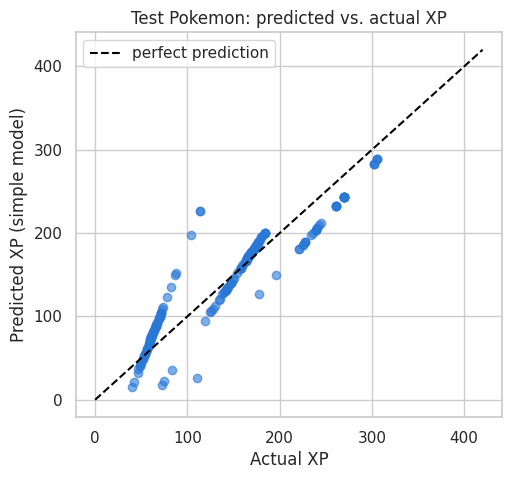

In [ ]:
plt.figure(figsize=(5.5, 5))
plt.scatter(actual, pred_a, color=BLUE, alpha=0.6)
plt.plot([0, 420], [0, 420], color="black", ls="--", label="perfect prediction")
plt.title("Test Pokemon: predicted vs. actual XP")
plt.xlabel("Actual XP")
plt.ylabel("Predicted XP (simple model)")
plt.legend()
plt.show()

Points on the dashed line are perfect predictions; the farther a point is from it, the bigger the miss. Two things stand out:

- The dots form several straight **streaks** instead of one cloud. The games seem to use slightly different XP rules for different groups of Pokemon (possibly by evolution stage), and one straight line cannot follow all of them.
- A few points sit far **above** the line on the left: Pokemon that give much less XP than the model expects. Who are they?

### Data Story 3 The Generation 7 Legendaries Give Less Than Half the XP

We use the simple model to predict every Pokemon and look at the **average residual** for legendary and non-legendary Pokemon in each generation.

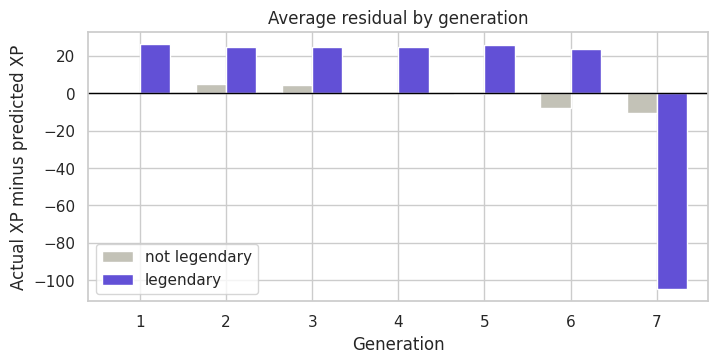

,pokemon,generation_id,total,base_experience
149,mewtwo,1,680,306
248,lugia,2,680,306
249,ho-oh,2,680,306
383,rayquaza,3,680,306
482,dialga,4,680,306
483,palkia,4,680,306
486,giratina-altered,4,680,306
642,reshiram,5,680,306
643,zekrom,5,680,306
715,xerneas,6,680,306


In [ ]:
poke["residual"] = poke["base_experience"] - model_a.predict(poke[["total"]])
by_gen = poke.groupby(["generation_id", "legendary"])["residual"].mean().unstack()
by_gen.columns = ["not legendary", "legendary"]

by_gen.plot(kind="bar", figsize=(8, 3.5), color=[GRAY, PURPLE], width=0.7)
plt.axhline(0, color="black", lw=1)
plt.title("Average residual by generation")
plt.xlabel("Generation")
plt.ylabel("Actual XP minus predicted XP")
plt.xticks(rotation=0)
plt.show()

poke[poke["total"] == 680][["pokemon", "generation_id", "total", "base_experience"]]

In Generations 1 to 6, legendary Pokemon give about 23 to 26 **more** XP than the line predicts. In Generation 7 they give over 100 **less**. The table shows why: every legendary with a total of 680 gives 306 XP, except **Solgaleo** and **Lunala** from Generation 7, which give only 136.

The games introduced in Generation 7 used a lower XP value for their new legendaries. Nothing in the base stats can tell the model that. The information it is missing is the **generation**.

**Lesson:** when residuals form a pattern instead of random noise, a feature is missing. Adding `generation_id` (or a "Generation 7" flag) as a feature would fix much of this error.

### Exercise 4 Evaluating Models

1. On the same training set, fit a model of `base_experience` that uses **only** `height` and `weight`. Report its MAE, RMSE and R-squared on the test set. How much worse is it than the model that uses the stats?
2. Add a feature `gen7 = (poke["generation_id"] == 7).astype(int)` to `poke`, split again with `random_state=42`, and fit a model on `total` and `gen7`. Do MAE and RMSE improve? Which one improves more, and why?

In [ ]:
# Your code here

## 6. From Regression to Classification

Many questions have a **yes or no** answer instead of a number. For example:

> Is this Pokemon **legendary**?

Predicting a category is called **classification**. Our label `legendary` is already 1 for yes and 0 for no. Before we build a model, let's see how good **you** are at this task.

### Interactive 4 Human vs. Machine

**You against the model.** The Pokedex below shows ten mystery Pokemon, one at a time. You see only their six stats and total, which is exactly what our model will see. Pokemon fans who recognize a Pokemon from its stats get bonus bragging rights.

For each one, do not just say yes or no: say **how sure** you are, by choosing one of four probabilities (5%, 30%, 70% or 95% legendary). Your answers are saved. We reveal the names, your score and the model's score in Section 7, and in Section 8 we score how well you judged your own confidence.

In [ ]:
# @title Interactive 4: Human vs. Machine (run this cell, then play)
MYSTERY = ["dragonite", "mewtwo", "tapu-koko", "pikachu", "slaking",
           "cosmog", "zapdos", "snorlax", "garchomp", "kyogre"]
mystery = poke.set_index("pokemon").loc[MYSTERY, STATS + ["total", "legendary"]].reset_index()
CHOICES = {"Definitely not (5%)": 0.05, "Probably not (30%)": 0.30,
           "Probably legendary (70%)": 0.70, "Definitely legendary (95%)": 0.95}
BAR_COLORS = [GREEN, ORANGE, YELLOW, BLUE, PURPLE, "#d6457a"]
my_answers, quiz = {}, {"i": 0}

def pokedex_card(i):
    row = mystery.iloc[i]
    bars = "".join(
        f"<div style='display:flex;align-items:center;margin:4px 0'>"
        f"<div style='width:120px'>{stat.replace('_', ' ').title()}</div>"
        f"<div style='width:40px;text-align:right;margin-right:10px'><b>{row[stat]}</b></div>"
        f"<div style='background:{color};height:14px;width:{row[stat] * 1.5:.0f}px;border-radius:4px'></div></div>"
        for stat, color in zip(STATS, BAR_COLORS))
    return (f"<div style='border:4px solid #c62f2f;border-radius:14px;padding:14px 18px;width:520px;font-family:sans-serif'>"
            f"<div style='font-size:20px'><b>POKEDEX: Mystery Pokemon {i + 1} of 10</b></div>"
            f"<div style='margin:4px 0 10px 0'>Name: <b>??????</b> &nbsp;&nbsp; Base stat total: <b>{row['total']}</b></div>"
            f"{bars}</div>")

def draw_quiz():
    if quiz["i"] < len(mystery):
        display(HTML(pokedex_card(quiz["i"])))
        print("How sure are you that this Pokemon is legendary?")
    else:
        print("All 10 answers saved. Wait for the reveal in Section 7.")
        print("Your answers:", {f"Mystery {k + 1}": v for k, v in my_answers.items()})

def answer(p):
    if quiz["i"] < len(mystery):
        my_answers[quiz["i"]] = p
        quiz["i"] += 1

def restart_quiz():
    my_answers.clear()
    quiz["i"] = 0

play(draw_quiz, {}, [(label, lambda p=p: answer(p), "info") for label, p in CHOICES.items()]
                    + [("Start over", restart_quiz, "")])

# Without the buttons, type your answers: my_answers = {0: 0.95, 1: 0.05, ...} (one per mystery Pokemon)

HBox(layout=Layout(flex_flow='row wrap'))

Output()

Now the obvious first idea for a model: use linear regression on the 0/1 label, and say "legendary" when the prediction is at least 0.5. Only about 8% of Pokemon are legendary. Does it work?

Share of legendary Pokemon: 0.084
Linear predictions range from -0.22 to 0.45
Pokemon with a prediction below 0: 267    at least 0.5: 0


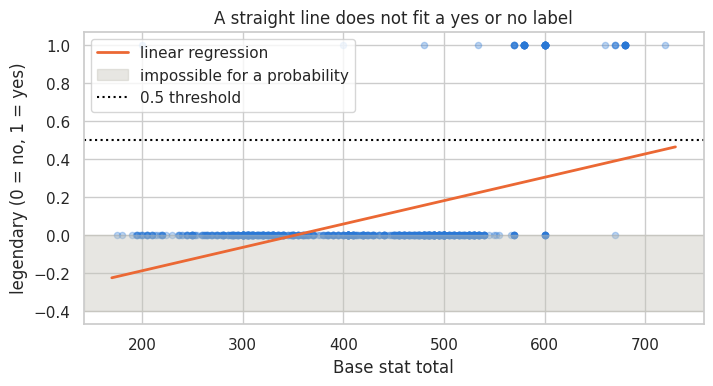

In [ ]:
print("Share of legendary Pokemon:", round(poke["legendary"].mean(), 3))

lin01 = LinearRegression().fit(poke[["total"]], poke["legendary"])
p_lin = lin01.predict(poke[["total"]])
print(f"Linear predictions range from {p_lin.min():.2f} to {p_lin.max():.2f}")
print("Pokemon with a prediction below 0:", (p_lin < 0).sum(), "   at least 0.5:", (p_lin >= 0.5).sum())

plt.figure(figsize=(8, 3.8))
plt.scatter(poke["total"], poke["legendary"], color=BLUE, alpha=0.3, s=20)
plt.plot(xs, lin01.predict(pd.DataFrame({"total": xs})), color=ORANGE, lw=2, label="linear regression")
plt.axhspan(-0.4, 0, color=GRAY, alpha=0.4, label="impossible for a probability")
plt.axhline(0.5, color="black", ls=":", label="0.5 threshold")
plt.title("A straight line does not fit a yes or no label")
plt.xlabel("Base stat total")
plt.ylabel("legendary (0 = no, 1 = yes)")
plt.legend(loc="upper left")
plt.show()

Two problems:

1. **Impossible values.** We would like to read a prediction as a probability, but for 267 weak Pokemon the line predicts a value **below 0**. A probability of -0.22 has no meaning.
2. **The wrong shape.** The line must go up by the same amount for every extra stat point. Because 92% of Pokemon are not legendary, the line stays low and never even reaches 0.5. With a 0.5 threshold, it would call **no** Pokemon legendary, not even Arceus! The probability should instead stay near 0 for weak Pokemon, then rise **steeply** and level off near 1, giving an S-shape.

Logistic regression fixes both problems.

## 7. Logistic Regression

Logistic regression keeps the linear score $z = b_0 + b_1 x$, but passes it through the **sigmoid function**, which squeezes any number into the range 0 to 1:

$$\sigma(z) = \frac{1}{1 + e^{-z}} \qquad \hat{p} = \sigma(b_0 + b_1 x)$$

The output $\hat{p}$ is the **predicted probability** that the label is 1.

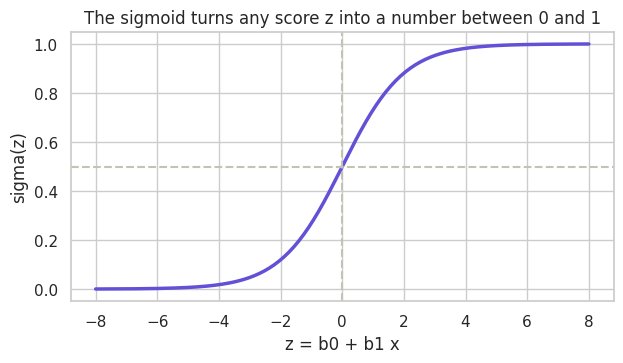

sigmoid(-4) = 0.018
sigmoid( 0) = 0.500
sigmoid( 4) = 0.982


In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
plt.figure(figsize=(7, 3.5))
plt.plot(z, sigmoid(z), color=PURPLE, lw=2.5)
plt.axhline(0.5, color=GRAY, ls="--")
plt.axvline(0, color=GRAY, ls="--")
plt.title("The sigmoid turns any score z into a number between 0 and 1")
plt.xlabel("z = b0 + b1 x")
plt.ylabel("sigma(z)")
plt.show()

for value in [-4, 0, 4]:
    print(f"sigmoid({value:2d}) = {sigmoid(value):.3f}")

- A large positive score gives a probability near 1.
- A large negative score gives a probability near 0.
- A score of exactly 0 gives 0.5.

Now fit a logistic regression on the training Pokemon from Section 6. `predict_proba` returns two columns: P(not legendary) and P(legendary). We keep the second.

z = -31.17 + 0.0544 x total


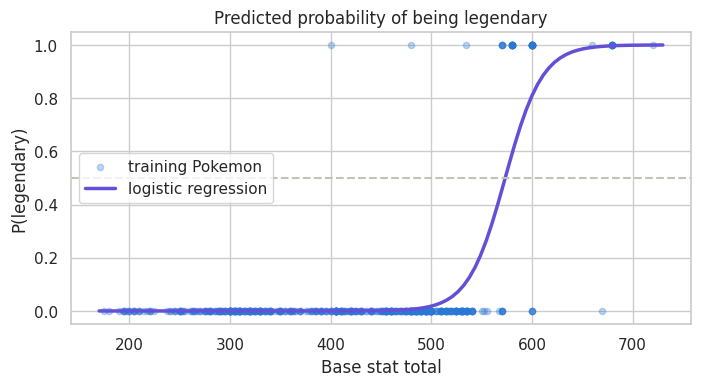

,total,P(legendary)
0,400,0.000
1,500,0.018
2,550,0.219
3,580,0.589
4,600,0.809
5,680,0.997


In [ ]:
from sklearn.linear_model import LogisticRegression

train, test = train_test_split(poke, test_size=0.25, random_state=42)     # same split as Section 6
logit = LogisticRegression().fit(train[["total"]], train["legendary"])
print(f"z = {logit.intercept_[0]:.2f} + {logit.coef_[0][0]:.4f} x total")

grid = pd.DataFrame({"total": xs})
plt.figure(figsize=(8, 3.8))
plt.scatter(train["total"], train["legendary"], color=BLUE, alpha=0.3, s=20, label="training Pokemon")
plt.plot(xs, logit.predict_proba(grid)[:, 1], color=PURPLE, lw=2.5, label="logistic regression")
plt.axhline(0.5, color=GRAY, ls="--")
plt.title("Predicted probability of being legendary")
plt.xlabel("Base stat total")
plt.ylabel("P(legendary)")
plt.legend(loc="center left")
plt.show()

examples = pd.DataFrame({"total": [400, 500, 550, 580, 600, 680]})
examples["P(legendary)"] = logit.predict_proba(examples)[:, 1].round(3)
examples

The S-shaped curve stays between 0 and 1 and levels off at both ends. A Pokemon with a total of 500 is almost certainly not legendary, while one with a total of 680 almost certainly is. The uncertain zone is a narrow band of totals around 550 to 600.

**Reading the coefficient:** a positive $b_1$ means the probability rises as x rises. More precisely, each extra stat point multiplies the **odds** $\frac{p}{1-p}$ by $e^{b_1}$.

### Human vs. Machine: the reveal

The model says "legendary" when its probability is at least 0.5, and so do you when you chose 70% or 95%. Green means correct, orange means wrong, and each cell shows the probability that was given. Post your score on the board.

You answered 0 of 10; missing answers count as 50%, which counts as 'not legendary'.


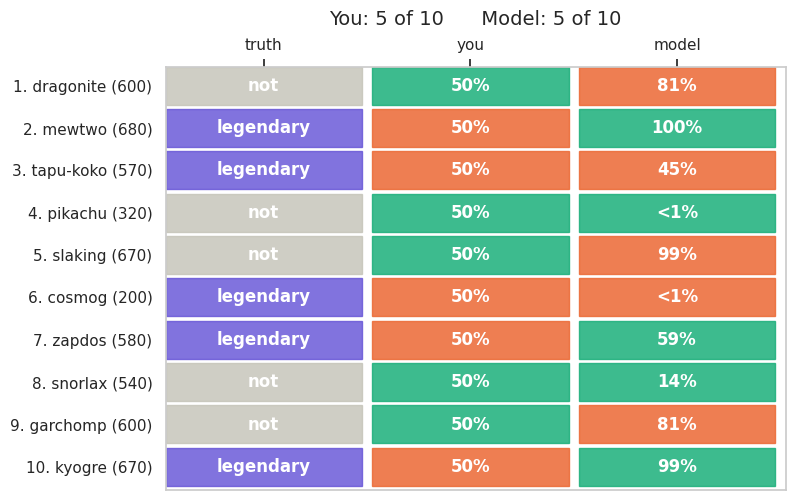

In [ ]:
# @title Human vs. Machine: the reveal (run this cell)
truth = mystery["legendary"].to_numpy()
reveal = pd.DataFrame({"pokemon": mystery["pokemon"], "total": mystery["total"],
                       "your P": [my_answers.get(i, 0.5) for i in range(10)],
                       "model P": logit.predict_proba(mystery[["total"]])[:, 1]})
you_right = (reveal["your P"] > 0.5).astype(int) == truth
model_right = (reveal["model P"] >= 0.5).astype(int) == truth
if len(my_answers) < 10:
    print(f"You answered {len(my_answers)} of 10; missing answers count as 50%, which counts as 'not legendary'.")

fig, ax = plt.subplots(figsize=(8, 5.5))
for r in range(10):
    ax.add_patch(plt.Rectangle((0, r), 0.95, 0.9, color=PURPLE if truth[r] else GRAY, alpha=0.8))
    ax.text(0.475, r + 0.45, "legendary" if truth[r] else "not", ha="center", va="center", color="white", weight="bold")
    for c, (prob, right) in enumerate([(reveal["your P"][r], you_right[r]), (reveal["model P"][r], model_right[r])], start=1):
        ax.add_patch(plt.Rectangle((c, r), 0.95, 0.9, color=GREEN if right else ORANGE, alpha=0.85))
        ax.text(c + 0.475, r + 0.45, f"{prob:.0%}" if prob >= 0.01 else "<1%", ha="center", va="center", color="white", weight="bold")
ax.set(xlim=(0, 3), ylim=(10, 0), xticks=[0.475, 1.475, 2.475], yticks=np.arange(10) + 0.45)
ax.set_xticklabels(["truth", "you", "model"])
ax.set_yticklabels([f"{i + 1}. {name} ({total})" for i, (name, total) in enumerate(zip(reveal["pokemon"], reveal["total"]))])
ax.xaxis.tick_top()
ax.grid(False)
ax.set_title(f"You: {you_right.sum()} of 10      Model: {model_right.sum()} of 10", pad=30, fontsize=14)
plt.show()

The model scores only **5 out of 10**, no better than a coin flip. Did the class beat it?

To be fair to the model, these ten were chosen **on purpose** to be tricky. On randomly chosen test Pokemon it does far better, as Section 8 shows. Its mistakes follow one simple rule: it trusts the total and nothing else.

- **Dragonite, Garchomp** and **Slaking** are very strong but not legendary, so the model calls them legendary.
- **Cosmog** and **Tapu Koko** are legendary but not very strong, so the model misses them.

Data Story 4 below shows that these mistakes are not random.

### Exercise 5 Logistic Regression

1. Fit logistic regressions of `legendary` on `speed` alone and on `hp` alone, and plot both probability curves on one chart. Which stat separates legendary Pokemon better? Compare their test accuracies.
2. Using the sigmoid formula with `logit.intercept_` and `logit.coef_`, compute **by hand** the probability that a Pokemon with a total of 560 is legendary. Check your answer with `predict_proba`.
3. **Bonus.** Most legendary Pokemon cannot breed, and the data records this as `egg_group_1 == "no-eggs"`. Add a 0/1 column `no_eggs` and fit a logistic regression on `total` and `no_eggs`. How many of the ten mystery Pokemon does it get right now?

In [ ]:
# Your code here

## 8. Decision Boundaries and Log Loss

### Decision boundary

To turn a probability into a yes or no, we use a **threshold**, usually 0.5: predict 1 if $\hat{p} \ge 0.5$.

Since $\sigma(z) = 0.5$ exactly when $z = 0$, the boundary is where $b_0 + b_1 x = 0$, that is $x = -b_0 / b_1$. On one side of this **decision boundary** the model says "legendary"; on the other side, "not legendary".

In [ ]:
boundary = -logit.intercept_[0] / logit.coef_[0][0]
print(f"Decision boundary: base stat total = {boundary:.1f}")

pred_class = logit.predict(test[["total"]])                 # uses the 0.5 threshold
accuracy = (pred_class == test["legendary"]).mean()
baseline = 1 - test["legendary"].mean()                     # always guess "not legendary"
print(f"Test accuracy: {accuracy:.3f}   Baseline (always 'not legendary'): {baseline:.3f}")

Decision boundary: base stat total = 573.4
Test accuracy: 0.975   Baseline (always 'not legendary'): 0.915


The model calls a Pokemon legendary when its total is above about 573. It is right for 97.5% of test Pokemon. That sounds great, but the baseline that **always** says "not legendary" is already right 91.5% of the time, because legendaries are rare. Always compare accuracy with a baseline.

### Interactive 5 The Legendary Research Lab

**You run a research lab with a budget.** Every Pokemon the model flags as legendary gets a research expedition.

- A **false alarm** (an expedition to a Pokemon that is not legendary) wastes money.
- A **missed legendary** is worse: a rival lab discovers it first.

The left panel shows the 201 test Pokemon as tiles, sorted from least to most likely legendary. The right panel shows your lab's total cost for every possible threshold.

**Missions:**

1. With the default prices (a false alarm costs 10 Pokedollars, a miss costs 100), find the cheapest threshold. Is it 0.5?
2. Make misses cost the same as false alarms. Where does the cheapest threshold move?
3. Make false alarms very expensive (100) and misses cheap (10). Now what?

In [ ]:
# @title Interactive 5: The Legendary Research Lab (run this cell, then play)
p_test = logit.predict_proba(test[["total"]])[:, 1]
truth_test = test["legendary"].to_numpy()
order = np.argsort(p_test, kind="stable")
THRESHOLDS = np.linspace(0.01, 0.99, 99)
TILE_NAMES = ["found a legendary", "false alarm", "missed legendary", "correctly ignored"]
TILE_COLORS = [GREEN, ORANGE, PURPLE, "#e3e3e3"]

def lab_cost(threshold, alarm_cost, miss_cost):
    flagged = p_test >= threshold
    return alarm_cost * np.sum(flagged & (truth_test == 0)) + miss_cost * np.sum(~flagged & (truth_test == 1))

def research_lab(threshold, alarm_cost, miss_cost):
    flagged = p_test >= threshold
    kind = np.select([flagged & (truth_test == 1), flagged & (truth_test == 0), ~flagged & (truth_test == 1)], [0, 1, 2], 3)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})

    for pos, i in enumerate(order):
        row, col = divmod(pos, 21)
        ax1.add_patch(plt.Rectangle((col, -row), 0.9, 0.9, color=TILE_COLORS[kind[i]]))
    for k in range(4):
        ax1.scatter([], [], marker="s", s=90, color=TILE_COLORS[k], label=f"{TILE_NAMES[k]}: {(kind == k).sum()}")
    ax1.set(xlim=(0, 21), ylim=(-9.2, 1), aspect="equal", title="201 test Pokemon, from least to most likely legendary")
    ax1.axis("off")
    ax1.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2, frameon=False)

    costs = [lab_cost(t, alarm_cost, miss_cost) for t in THRESHOLDS]
    best = THRESHOLDS[int(np.argmin(costs))]
    ax2.plot(THRESHOLDS, costs, color=BLUE, lw=2)
    ax2.scatter(best, min(costs), marker="*", s=350, color=GREEN, edgecolor="black", zorder=4, label=f"cheapest: threshold {best:.2f}")
    ax2.scatter(threshold, lab_cost(threshold, alarm_cost, miss_cost), s=150, color=ORANGE, edgecolor="black", zorder=5, label="your lab")
    ax2.set(xlabel="Threshold", ylabel="Total cost (Pokedollars)",
            title=f"Your lab's total cost: {lab_cost(threshold, alarm_cost, miss_cost):,} Pokedollars")
    ax2.legend()
    plt.tight_layout()
    plt.show()

    print("False alarms:", ", ".join(test["pokemon"].to_numpy()[kind == 1]) or "none")
    print("Missed:      ", ", ".join(test["pokemon"].to_numpy()[kind == 2]) or "none")

play(research_lab,
     {"threshold": slider(widgets.FloatSlider, 0.50, 0.01, 0.99, 0.01, "threshold"),
      "alarm_cost": slider(widgets.IntSlider, 10, 0, 100, 5, "cost of a false alarm"),
      "miss_cost": slider(widgets.IntSlider, 100, 0, 300, 10, "cost of a miss")})

# Without the sliders: research_lab(0.3, 10, 100)

HBox()

Output()

**Debrief.** The 0.5 threshold is only the best choice when both mistakes cost the same. When a miss is ten times worse than a false alarm, the cheapest threshold drops, and the lab flags more Pokemon. The same reasoning is used for real decisions: a medical test that screens for a serious disease uses a low threshold, because a missed case is far worse than a false alarm. No threshold removes both kinds of mistakes, because some legendaries are weaker than some non-legendaries.

### Data Story 4 Dragonite Is Not Legendary, but the Model Thinks So

Which Pokemon end up on the **wrong side** of the boundary?

In [ ]:
poke["p_legendary"] = logit.predict_proba(poke[["total"]])[:, 1]
cols = ["pokemon", "total", "p_legendary"]

print("Not legendary, but the model says yes:")
print(poke[(poke["legendary"] == 0) & (poke["p_legendary"] >= 0.5)][cols].sort_values("total", ascending=False).round(3).to_string(index=False))
print("\nLegendary, but the model says no:")
print(poke[(poke["legendary"] == 1) & (poke["p_legendary"] < 0.5)][cols].sort_values("total").round(3).to_string(index=False))

Not legendary, but the model says yes:
  pokemon  total  p_legendary
  slaking    670        0.995
dragonite    600        0.809
tyranitar    600        0.809
salamence    600        0.809
metagross    600        0.809
 garchomp    600        0.809
hydreigon    600        0.809
   goodra    600        0.809
  kommo-o    600        0.809

Legendary, but the model says no:
  pokemon  total  p_legendary
   cosmog    200        0.000
  cosmoem    400        0.000
   phione    480        0.006
type-null    534        0.105
tapu-koko    570        0.454
tapu-lele    570        0.454
tapu-bulu    570        0.454
 silvally    570        0.454
tapu-fini    570        0.454


The false alarms are famous: **Dragonite, Tyranitar, Salamence, Metagross, Garchomp, Hydreigon, Goodra** and **Kommo-o**. Players call them **pseudo-legendary** Pokemon: each one is the final form of a rare, slow-growing line, and each has a base stat total of exactly 600, the same as many legendaries. **Slaking** (670) is a special case: its huge stats come with an ability that makes it rest every other turn.

The misses on the other side are legendaries designed to be weak: **Cosmog** and **Cosmoem** (baby forms of Solgaleo and Lunala), **Phione**, and **Type: Null**. The four **Tapu** guardians and Silvally sit at 570, just below the boundary.

**Lesson:** classification errors are often meaningful. Here they reveal a category (pseudo-legendaries) that the label does not record.

### Log loss: the cost function for classification

To train logistic regression, we need a cost function. MSE is a poor choice here: with the sigmoid inside, its surface is no longer a nice bowl, and it hardly punishes a model that is **confidently wrong**. Instead we use **log loss**, also called **binary cross-entropy**:

$$\text{Log loss} = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log(\hat{p}_i) + (1 - y_i)\log(1 - \hat{p}_i)\Big]$$

Only one of the two terms is active for each row:

- If $y = 1$, the penalty is $-\log(\hat{p})$: small when $\hat{p}$ is near 1, huge when $\hat{p}$ is near 0.
- If $y = 0$, the penalty is $-\log(1 - \hat{p})$: small when $\hat{p}$ is near 0, huge when $\hat{p}$ is near 1.

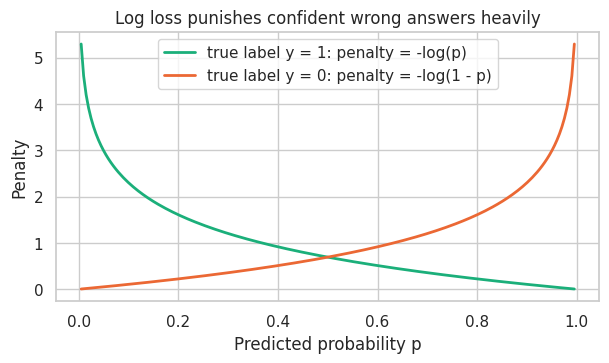

True label 1, predicted p =  0.9: penalty = 0.11
True label 1, predicted p =  0.5: penalty = 0.69
True label 1, predicted p =  0.1: penalty = 2.30
True label 1, predicted p = 0.01: penalty = 4.61


In [ ]:
p = np.linspace(0.005, 0.995, 200)
plt.figure(figsize=(7, 3.5))
plt.plot(p, -np.log(p), color=GREEN, lw=2, label="true label y = 1: penalty = -log(p)")
plt.plot(p, -np.log(1 - p), color=ORANGE, lw=2, label="true label y = 0: penalty = -log(1 - p)")
plt.title("Log loss punishes confident wrong answers heavily")
plt.xlabel("Predicted probability p")
plt.ylabel("Penalty")
plt.legend(loc="upper center")
plt.show()

for prob in [0.9, 0.5, 0.1, 0.01]:
    print(f"True label 1, predicted p = {prob:4}: penalty = {-np.log(prob):.2f}")

Predicting 0.9 for a true legendary costs 0.11, while predicting 0.01 costs 4.61, about 40 times more. Log loss rewards models that are confident only when they are right.

### Human vs. Machine, round 2: who judged their confidence better?

Accuracy only checks yes or no. Log loss also checks **how sure** you were. Let's score your Pokedex answers from Interactive 4 with log loss. Lower is better.

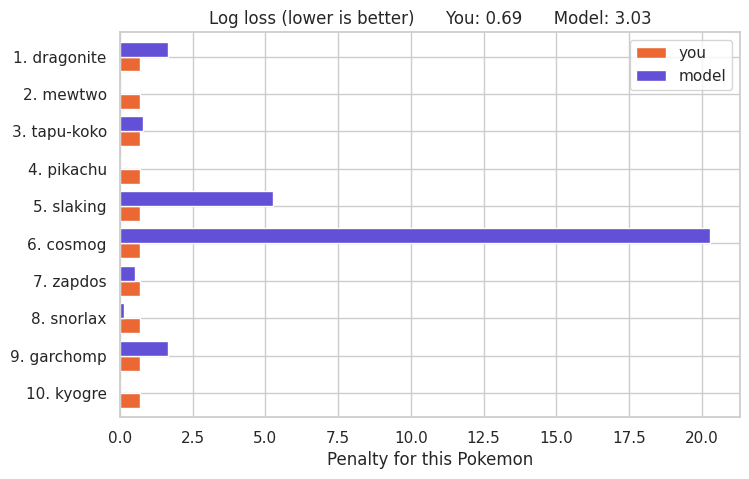

In [ ]:
# @title Human vs. Machine, round 2: log loss (run this cell)
def penalty(y_true, p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

pen = pd.DataFrame({"you": penalty(truth, reveal["your P"].to_numpy()), "model": penalty(truth, reveal["model P"].to_numpy())},
                   index=[f"{i + 1}. {name}" for i, name in enumerate(reveal["pokemon"])])
pen.iloc[::-1].plot(kind="barh", figsize=(8, 5), color=[ORANGE, PURPLE], width=0.8)
plt.title(f"Log loss (lower is better)      You: {pen['you'].mean():.2f}      Model: {pen['model'].mean():.2f}")
plt.xlabel("Penalty for this Pokemon")
plt.show()

Look at **Cosmog**. Its total is only 200, so the model was more than 99.9999% sure that it is not legendary. It was wrong, and log loss charges a penalty of about 20 for that single answer, more than the model's other nine penalties put together. Your penalty can never be higher than 3.0, because you were never more than 95% sure.

**Lesson:** a model that is confidently wrong is punished hard. This is why log loss is the cost function used to train logistic regression. Like the MSE, it is a single bowl, so **gradient descent** finds its bottom: exactly the same idea as Section 4, with a different cost.

## 9. The Bias-Variance Trade-off and Regularization

We can make a model more **complex** (more flexible) by adding powers of a feature: $x^2, x^3, \dots, x^d$. This is **polynomial regression**. It is still linear regression, just with extra columns. A higher degree $d$ gives a curve that can bend more.

More flexible is not always better:

- **Underfitting (high bias):** the model is too simple to capture the pattern. It is wrong in the same way no matter which data we train it on.
- **Overfitting (high variance):** the model is so flexible that it learns the noise in the training data. Train it on a different sample and you get a very different model.

**Regularization** is a way to control complexity. Overfit models usually have very large coefficients, and **Ridge** regression adds a penalty for them to the cost function:

$$\text{Ridge (L2):} \quad \text{Cost} = \text{squared error} + \alpha \sum_j b_j^2$$

The number $\alpha$ (alpha) sets the strength of the penalty. $\alpha = 0$ gives plain linear regression; a very large $\alpha$ pushes all coefficients toward 0.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso

curve_x = pd.DataFrame({"total": np.linspace(poke["total"].min(), poke["total"].max(), 300)})

def poly_model(degree, alpha=0):
    # add x, x^2, ..., x^degree, scale them, then fit a (possibly penalized) linear regression
    final = LinearRegression() if alpha == 0 else Ridge(alpha=alpha)
    return make_pipeline(PolynomialFeatures(degree), StandardScaler(), final)

def rmse(model, data):
    return np.sqrt(mean_squared_error(data["base_experience"], model.predict(data[["total"]])))

### Interactive 6 Ghost Curves

**You are a scientist who repeats the same experiment 20 times.** Each time, you collect a different random sample of Pokemon, train the same kind of model on it, and draw the resulting curve. Each thin orange curve is one of these 20 "ghosts". The black curve is their average.

- **Variance** is how much the ghosts disagree with each other (the "wobble").
- **Bias** is how far the average curve is from the real pattern.

**Missions:**

1. Degree 0 with 30 Pokemon: the ghosts agree with each other, but what is wrong with them?
2. Degree 8 with 30 Pokemon: what do the ghosts look like now? Press **New random experiments** a few times.
3. Keep degree 8 and fix the ghosts **without** changing the degree. Find two different ways.

In [ ]:
# @title Interactive 6: Ghost Curves (run this cell, then play)
ghosts = {"seed": 0}

def ghost_curves(degree, alpha, train_size):
    rng = np.random.default_rng(ghosts["seed"])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2, 1]})
    ax1.scatter(poke["total"], poke["base_experience"], color=GRAY, s=8, alpha=0.4)
    curves, test_rmses = [], []
    for k in range(20):
        idx = rng.choice(poke.index, size=train_size, replace=False)
        m = poly_model(degree, alpha).fit(poke.loc[idx, ["total"]], poke.loc[idx, "base_experience"])
        curves.append(m.predict(curve_x))
        test_rmses.append(rmse(m, poke.drop(idx)))
        ax1.plot(curve_x["total"], curves[-1], color=ORANGE, lw=1, alpha=0.6, label="20 ghosts" if k == 0 else None)
    ax1.plot(curve_x["total"], np.mean(curves, axis=0), color="black", lw=2.5, label="average of the ghosts")
    wobble = np.std(curves, axis=0).mean()
    ax1.set(ylim=(0, 450), xlabel="Base stat total", ylabel="Base experience (XP)",
            title=f"Degree {degree}, alpha {alpha}, {train_size} training Pokemon each      wobble = {wobble:,.0f} XP")
    ax1.legend(loc="upper left")

    ax2.scatter(test_rmses, np.random.default_rng(1).uniform(-1, 1, 20), color=ORANGE, s=50, edgecolor="black")
    ax2.axvline(np.mean(test_rmses), color="black", lw=2, label=f"average: {np.mean(test_rmses):,.0f} XP")
    ax2.set(xscale="log", xlim=(20, max(200, 2 * max(test_rmses))), ylim=(-2, 2), yticks=[],
            xlabel="Test RMSE in XP (log scale)", title="Test error of each ghost")
    ax2.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

def new_experiments():
    ghosts["seed"] += 1

play(ghost_curves,
     {"degree": slider(widgets.IntSlider, 0, 0, 8, 1, "polynomial degree"),
      "alpha": widgets.Dropdown(options=[0, 0.1, 1, 10, 100, 1000], value=0, description="Ridge alpha"),
      "train_size": widgets.Dropdown(options=[20, 30, 60, 120, 300], value=30, description="Pokemon per experiment",
                                     style={"description_width": "initial"})},
     [("New random experiments", new_experiments, "primary")])

# Without the sliders: ghost_curves(8, 0, 30)

Output()

**Debrief.**

- **Degree 0** (a flat line): the ghosts agree with each other, so variance is low, but all of them miss the upward trend: **high bias**.
- **Degree 8** with 30 Pokemon: every ghost bends to its own 30 training Pokemon, and the ghosts fly apart, especially at the edges where training data is rare: **high variance**.
- The two fixes for degree 8 are **more data** (300 Pokemon per experiment) and **regularization** (Ridge alpha around 10). Both calm the ghosts down without changing the degree.

The same story in one chart: train on one sample of 30 Pokemon, test on the other 772, and measure the error for every degree.

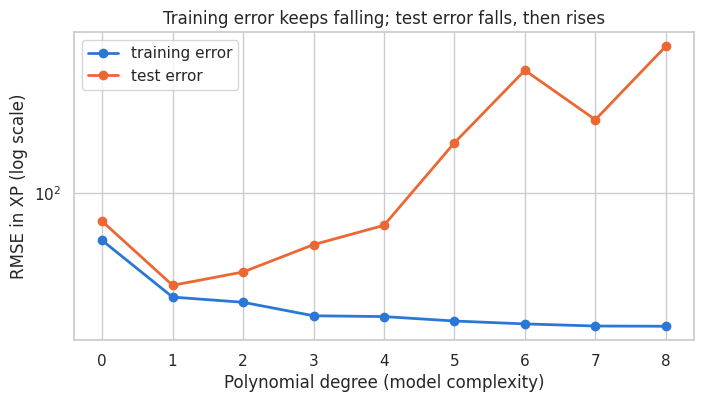

,train RMSE,test RMSE
degree,,
0,59.7,73.4
1,32.5,36.9
2,30.7,42.5
3,26.6,57.1
4,26.3,70.3
5,25.1,170.9
6,24.3,372.9
7,23.8,219.1
8,23.7,483.1


In [ ]:
small_train, big_test = train_test_split(poke, train_size=30, random_state=11)
errors = pd.DataFrame([{"degree": d,
                        "train RMSE": rmse(poly_model(d).fit(small_train[["total"]], small_train["base_experience"]), small_train),
                        "test RMSE": rmse(poly_model(d).fit(small_train[["total"]], small_train["base_experience"]), big_test)}
                       for d in range(9)]).set_index("degree")

plt.figure(figsize=(8, 4))
plt.plot(errors.index, errors["train RMSE"], "o-", color=BLUE, lw=2, label="training error")
plt.plot(errors.index, errors["test RMSE"], "o-", color=ORANGE, lw=2, label="test error")
plt.yscale("log")
plt.title("Training error keeps falling; test error falls, then rises")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("RMSE in XP (log scale)")
plt.legend()
plt.show()
errors.round(1)

This is the **bias-variance trade-off**: as complexity grows, training error goes down, but test error goes down at first (less bias) and then up (more variance). The best model is at the bottom of the test error curve: degree 1, the straight line from Section 2.

| | Underfitting | Good fit | Overfitting |
|---|---|---|---|
| Model | too simple | right complexity | too complex |
| Training error | high | low | very low |
| Test error | high | low | high |
| Ghost curves | agree, but all wrong | agree, and follow the data | disagree wildly |
| Problem | high bias | balance | high variance |
| Possible fixes | more features, more flexible model | | more data, simpler model, **regularization** |

### Ridge vs. Lasso

**Lasso** is a second kind of regularization. Its penalty uses absolute values, $\alpha \sum_j \lvert b_j \rvert$, and it can set some coefficients to **exactly zero**, which removes those features from the model.

| | Ridge (L2) | Lasso (L1) |
|---|---|---|
| Penalty | sum of squared coefficients | sum of absolute coefficients |
| Effect | shrinks all coefficients toward 0 | shrinks, and sets some **exactly** to 0 |
| Keeps all features? | yes | no, it selects features |
| Good when | many features each matter a little | only a few features really matter |

Features must be **scaled** before Ridge or Lasso, so that the penalty treats all coefficients fairly. To choose alpha, try several values and keep the one with the best score on unseen data; `RidgeCV` and `LassoCV` do this automatically.

### Exercise 6 Bias, Variance and Regularization

1. Repeat the error table with `train_size=100` instead of 30 (keep `random_state=11`). Does the test error still explode at degree 8? Explain your answer using the ghost curves.
2. Build a table of 25 features (height, the six stats, and one 0/1 column for each of the 18 types), scale it, and fit `Lasso(alpha=5)` to predict XP on the training set from Section 5. Which features does Lasso keep? Does a Pokemon's type matter once we know its stats?

<details>
<summary><b>Hint</b></summary>

```python
TYPES = sorted(set(poke["type_1"]) | set(poke["type_2"].dropna()))
type_flags = pd.DataFrame({f"type_{t}": ((poke["type_1"] == t) | (poke["type_2"] == t)).astype(float) for t in TYPES})
X_all = pd.concat([poke[["height"] + STATS], type_flags], axis=1)
```

Use `StandardScaler().fit(X_all.loc[train.index])`, then look at `pd.Series(lasso.coef_, index=X_all.columns)`.

</details>

In [ ]:
# Your code here

## 10. Final Challenge

### Interactive 7 The Pokemon Designer

**You are a game designer.** Name your new Pokemon and set its six stats. The radar chart compares its shape with the average legendary and the average regular Pokemon, and your Pokedex entry shows what both of our models think of it:

- its **predicted XP** (the linear regression from Section 2),
- its **probability of being legendary** (the logistic regression from Section 7), and
- its three **closest real relatives**, the Pokemon with the most similar stats.

**Complete the five missions** on the mission board. Completed missions stay completed, so you can work on them in any order. The first student or team to complete all five wins.

In [ ]:
# @title Interactive 7: The Pokemon Designer (run this cell, then play)
AVG_LEGEND = poke.loc[poke["legendary"] == 1, STATS].mean()
AVG_OTHER = poke.loc[poke["legendary"] == 0, STATS].mean()
LABELS = ["HP", "Attack", "Defense", "Sp. Attack", "Sp. Defense", "Speed"]
ANGLES = np.linspace(0, 2 * np.pi, 6, endpoint=False).tolist() + [0]
MISSIONS = {
    "Fool the Machine: a total below 600 that the model calls legendary": lambda s, total, xp, p, gap: total < 600 and p >= 0.5,
    "On the Fence: a probability of being legendary between 45% and 55%": lambda s, total, xp, p, gap: 0.45 <= p <= 0.55,
    "Glass Cannon: Attack of 150 or more, but not legendary": lambda s, total, xp, p, gap: s["attack"] >= 150 and p < 0.5,
    "Worth 200 XP: a predicted XP between 195 and 205": lambda s, total, xp, p, gap: 195 <= xp <= 205,
    "Long-Lost Twin: stats within 15 points of a real Pokemon": lambda s, total, xp, p, gap: gap < 15,
}
completed = set()

def designer(name, hp, attack, defense, special_attack, special_defense, speed):
    mine = pd.Series([hp, attack, defense, special_attack, special_defense, speed], index=STATS)
    total = int(mine.sum())
    xp = simple.predict(pd.DataFrame({"total": [total]}))[0]
    p = logit.predict_proba(pd.DataFrame({"total": [total]}))[0, 1]
    distance = np.sqrt(((poke[STATS] - mine) ** 2).sum(axis=1))
    twins = poke.loc[distance.nsmallest(3).index]
    for mission, check in MISSIONS.items():
        if check(mine, total, xp, p, distance.min()):
            completed.add(mission)

    fig = plt.figure(figsize=(13, 4.6))
    radar = fig.add_subplot(1, 2, 1, polar=True)
    for values, color, label in [(mine, ORANGE, name), (AVG_LEGEND, PURPLE, "average legendary"), (AVG_OTHER, GRAY, "average other")]:
        v = list(values) + [values.iloc[0]]
        radar.plot(ANGLES, v, color=color, lw=2, label=label)
        radar.fill(ANGLES, v, color=color, alpha=0.15)
    radar.set_xticks(ANGLES[:-1])
    radar.set_xticklabels(LABELS)
    radar.set_ylim(0, 255)
    radar.set_yticks([50, 100, 150, 200, 250])
    radar.set_rlabel_position(90)
    radar.legend(loc="upper left", bbox_to_anchor=(1.05, 1.1))

    meter = fig.add_subplot(2, 2, 2)
    meter.barh([0], [p], color=PURPLE if p >= 0.5 else GRAY)
    meter.axvline(0.5, color="black", ls="--")
    meter.set(xlim=(0, 1), yticks=[], title=f"Legendary meter: {p:.0%}")
    xp_meter = fig.add_subplot(2, 2, 4)
    xp_meter.barh([0], [xp], color=BLUE)
    xp_meter.set(xlim=(0, 400), yticks=[], title=f"Predicted XP: {xp:.0f}")
    plt.tight_layout()
    plt.show()

    relatives = "".join(f"<li>{r.pokemon} (total {r.total}, {r.base_experience} XP{', legendary' if r.legendary else ''})</li>"
                        for r in twins.itertuples())
    board = "".join(f"<li style='color:{GREEN if m in completed else '#888'}'><b>{'[DONE]' if m in completed else '[ &nbsp; &nbsp; ]'}</b> {m}</li>"
                    for m in MISSIONS)
    display(HTML(
        f"<div style='display:flex;gap:20px;font-family:sans-serif'>"
        f"<div style='border:4px solid #c62f2f;border-radius:14px;padding:12px 16px;width:380px'>"
        f"<div style='font-size:20px'><b>POKEDEX: {name}</b></div>"
        f"Base stat total: <b>{total}</b><br>The model says: <b>{'LEGENDARY' if p >= 0.5 else 'not legendary'}</b>"
        f"<br>Closest real relatives:<ul style='margin:4px 0'>{relatives}</ul></div>"
        f"<div style='border:2px solid #888;border-radius:14px;padding:12px 16px;width:520px'>"
        f"<div style='font-size:18px'><b>Mission board: {len(completed)} of {len(MISSIONS)} completed</b></div>"
        f"<ul style='list-style:none;padding-left:0'>{board}</ul></div></div>"))

controls = {"name": widgets.Text(value="Mysterion", description="Name", continuous_update=False)}
controls.update({s: slider(widgets.IntSlider, v, 5, 255, 5, label) for s, v, label in zip(STATS, [120, 60, 60, 120, 60, 60], LABELS)})
play(designer, controls, [("Reset missions", completed.clear, "")])

# Without the sliders: designer("Mysterion", 100, 120, 90, 110, 90, 100)

Output()

How did you complete Long-Lost Twin? One quick route: some real Pokemon have all six stats equal. Set every stat to 80 and meet **Glalie**, or to 70 and meet **Castform**.

Notice also that both models only look at the **total**. You can move points from Speed to Defense and the predictions stay the same; only the closest relatives change. That is a limitation of one-feature models, and a hint for the tournament below.

### Exercise 7 The XP Prediction Tournament

Your final challenge brings together everything from this course. Work in teams of two or three.

**Goal:** build the model with the **lowest RMSE** for predicting `base_experience`. The `submit` function below trains your model on 601 Pokemon, tests it on 201 locked **vault** Pokemon that your model never sees during training, and adds your best score to the leaderboard.

**Rules:**

1. You may use any column of `poke`, and you may create new columns (for example flags, interactions or powers).
2. You may use any model from this course: `LinearRegression`, `Ridge`, `Lasso`, polynomial features, pipelines with `StandardScaler`.
3. Do not look at the vault Pokemon or tune your model on them by hand. That would be cheating, like reading the exam before writing it.

**Score to beat:** the simple model on `total` alone scores an RMSE of about 36.6 XP (the dashed line on the leaderboard). At the end of class, each team reads out its best feature list, and the instructor submits all of them on the projector for the final ranking.

In [ ]:
TRAIN_IDX, VAULT_IDX = train_test_split(poke.index, test_size=0.25, random_state=2026)
LEADERBOARD = {}

def tournament_score(model, features):
    model.fit(poke.loc[TRAIN_IDX, features], poke.loc[TRAIN_IDX, "base_experience"])
    pred = model.predict(poke.loc[VAULT_IDX, features])
    return np.sqrt(mean_squared_error(poke.loc[VAULT_IDX, "base_experience"], pred))

BASELINE = tournament_score(LinearRegression(), ["total"])

In [ ]:
# @title The tournament leaderboard (run this cell)
def submit(team, model, features):
    score = tournament_score(model, features)
    print(f"{team}: RMSE = {score:.2f} XP with {features}")
    if team not in LEADERBOARD or score < LEADERBOARD[team]["RMSE"]:
        LEADERBOARD[team] = {"RMSE": score, "features": ", ".join(features)}
    board = pd.DataFrame(LEADERBOARD).T.astype({"RMSE": float}).sort_values("RMSE")
    places = ["1st", "2nd", "3rd"] + [f"{i}th" for i in range(4, len(board) + 1)]

    plt.figure(figsize=(8, 1 + 0.5 * len(board)))
    plt.barh([f"{pl}  {t}" for pl, t in zip(places, board.index)][::-1], board["RMSE"][::-1],
             color=[YELLOW if i == 0 else BLUE for i in range(len(board))][::-1])
    plt.axvline(BASELINE, color=ORANGE, ls="--", lw=2, label=f"score to beat: {BASELINE:.1f}")
    plt.xlim(0, max(BASELINE, board["RMSE"].max()) * 1.15)
    plt.xlabel("Vault RMSE in XP (lower is better)")
    plt.title("Tournament leaderboard")
    plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.show()

<details>
<summary><b>Hint</b></summary>

Look back at the Data Stories. Which group of Pokemon gave much more XP than expected (Data Story 1)? Which group gave much less (Data Story 3)? A 0/1 column for each group lets a linear model handle them separately. An **interaction** column, such as `poke["legendary"] * poke["gen7"]`, is 1 only when both are true.

</details>

Professor Oak: RMSE = 36.60 XP with ['total']


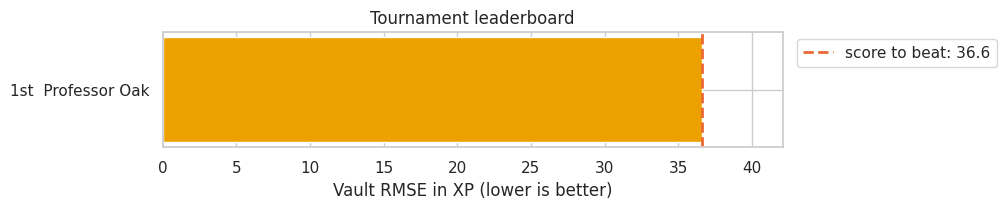

In [ ]:
# Your team's code here
submit("Professor Oak", LinearRegression(), ["total"])      # example submission

# Example: poke["gen7"] = (poke["generation_id"] == 7).astype(int)
#          submit("Team Rocket", LinearRegression(), ["total", "gen7"])

## Summary

| Topic | Key idea | Where we played with it |
|---|---|---|
| Linear regression | predict a number with a line, $\hat{y} = b_0 + b_1 x$ | XP from base stat total |
| Cost function | one number for how bad a model is; MSE is the average squared residual | Fit the Line by Hand: squares and the cost map |
| Multiple regression | each coefficient holds the other features fixed | four healers make HP look twice as valuable |
| Gradient descent | step downhill along the negative gradient | Lost in the Fog |
| Learning rate | step size: too small is slow, too large diverges | The Gradient Descent Race |
| Batch, SGD, mini-batch | all rows, one row, or a small group per step | smooth vs. noisy paths |
| Evaluation | MAE, MSE, RMSE, R-squared on a test set | Generation 7 legendaries give less XP |
| Regression to classification | a line gives impossible "probabilities" | the line never calls Arceus legendary |
| Logistic regression | sigmoid turns a score into a probability | Human vs. Machine |
| Decision boundary | the threshold should depend on the cost of each mistake | The Legendary Research Lab |
| Log loss | punishes confident mistakes | the model's Cosmog penalty |
| Bias-variance trade-off | too simple is wrong the same way; too complex is wrong a different way every time | Ghost Curves |
| Regularization | penalize large coefficients; Lasso also selects features | Ridge calms the degree 8 ghosts |

### Where to go from here

You now know the core loop behind almost every machine learning model: choose a model, choose a **cost function**, minimize it with **gradient descent**, and judge the result on **data the model has never seen**. Neural networks use exactly this loop with a much more flexible model. Natural next topics are decision trees and random forests, cross-validation, and neural networks.

Thank you for a great bootcamp, and good luck with your projects.